# Predicting Climate-Driven Population Displacement
### A hybrid **Bayesian Model Averaging (BMA) + Gradient Boosting** model
*21CSC305P / Machine Learning — Unit 5: Combining Models*

**Goal:** predict how many people an extreme weather event (flood, storm, wildfire, drought, extreme heat/cold,
landslide) will displace, with an uncertainty range, so local authorities can plan shelters and aid in advance.

**Data (real, public):**
* IDMC — *Internal displacements (new displacements) associated with disasters* (HDX, CC BY-IGO)
  https://data.humdata.org/dataset/idmc-internal-displacements-new-displacements-associated-with-disasters
* World Bank Open Data API — population, urban population %, GDP per capita, population density
  https://data.worldbank.org

## 1. Setup

In [1]:
import itertools, json, math, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
C_BMA, C_GB, C_HYB = "#2a78d6", "#eb6834", "#1f9d6b"
np.random.seed(42)

## 2. Load the real data

In [2]:
IDMC_URL = ("https://data.humdata.org/dataset/bab7e849-6ac6-4936-b343-17444bff2bdb/resource/"
            "f760be9f-9a6a-4e59-a1be-163a42f5e98d/download/"
            "internal-displacements-new-displacements-associated-with-disasters.csv")
raw = pd.read_csv(IDMC_URL)
print(raw.shape)
raw.head()

(29698, 21)


,iso3,country_name,year,start_date,start_date_accuracy,end_date,end_date_accuracy,event_name,hazard_category,hazard_category_name,...,hazard_sub_category_name,hazard_type,hazard_type_name,hazard_sub_type,hazard_subtype_name,new_displacement,new_displacement_rounded,total_displacement,total_displacement_rounded,event_codes
0,PHL,Philippines,2008,2008-01-01,Month,2008-06-23,Day,Philippines: Storm - 01/01/2008,2,Weather related,...,Meteorological,14,Storm,21,NaN,2039155,2039000,NaN,NaN,[]
1,IDN,Indonesia,2008,2008-01-02,Day,2008-02-06,Day,Indonesia: Flood - 02/01/2008,2,Weather related,...,Hydrological,10,Flood,13,NaN,49653,50000,NaN,NaN,[]
2,TGO,Togo,2008,2008-01-07,Day,2008-08-08,Day,Togo: Flood - 07/01/2008,2,Weather related,...,Hydrological,10,Flood,13,NaN,2000,2000,NaN,NaN,[]
3,TUR,Türkiye,2008,2008-01-08,Day,2008-08-05,Day,Türkiye: Wildfire - 08/01/2008,2,Weather related,...,Climatological,9,Wildfire,11,NaN,300,300,NaN,NaN,[]
4,USA,United States of America,2008,2008-01-09,Day,2008-09-01,Day,United States: Storm - 09/01/2008,2,Weather related,...,Meteorological,14,Storm,21,NaN,1900000,1900000,NaN,NaN,[]


In [3]:
def world_bank(indicator, name):
    url = (f"https://api.worldbank.org/v2/country/all/indicator/{indicator}"
           "?format=json&per_page=20000&date=2008:2025")
    rows = json.load(urllib.request.urlopen(url))[1]
    return pd.DataFrame([{"iso3": r["countryiso3code"], "year": int(r["date"]), name: r["value"]}
                         for r in rows if r["countryiso3code"]])

wb = None
for ind, name in [("SP.POP.TOTL", "population"), ("SP.URB.TOTL.IN.ZS", "urban_pct"),
                  ("NY.GDP.PCAP.CD", "gdp_per_capita"), ("EN.POP.DNST", "pop_density")]:
    part = world_bank(ind, name)
    wb = part if wb is None else wb.merge(part, on=["iso3", "year"], how="outer")
# carry the latest value forward/backward inside each country (World Bank lags a year or two)
wb = wb.sort_values(["iso3", "year"])
wb[["population", "urban_pct", "gdp_per_capita", "pop_density"]] = (
    wb.groupby("iso3")[["population", "urban_pct", "gdp_per_capita", "pop_density"]].transform(lambda s: s.ffill().bfill()))
print(wb.shape)
wb.tail()

(4698, 6)


,iso3,year,population,urban_pct,gdp_per_capita,pop_density
4693,ZWE,2021,15797210,37.869206,2613.616741,40.835492
4694,ZWE,2022,16069056,38.705521,2536.401971,41.538209
4695,ZWE,2023,16340822,39.291937,2195.225020,42.240719
4696,ZWE,2024,16634373,39.893372,2496.155150,42.999542
4697,ZWE,2025,16950795,40.495129,3021.430199,42.999542


## 3. Clean the data and build features
* Keep only **weather / climate-related** events (IDMC category "Weather related").
* Target **y = log(1 + people displaced)** — displacement ranges from 1 to millions, so the log scale keeps a few
  giant storms from dominating the model.

In [4]:
df = raw[raw["hazard_category_name"] == "Weather related"].copy()
df = df[df["new_displacement"].fillna(0) > 0]
df["start"] = pd.to_datetime(df["start_date"], errors="coerce")
df["end"] = pd.to_datetime(df["end_date"], errors="coerce")
df = df.dropna(subset=["start"])
df["month"] = df["start"].dt.month
df["duration_days"] = (df["end"] - df["start"]).dt.days.clip(lower=0, upper=365).fillna(0)
df["multi_country"] = df["event_name"].str.contains(r"countries", case=False, na=False).astype(int)
df["named_storm"] = df["event_name"].str.contains(r"hurricane|typhoon|cyclone|tropical", case=False, na=False).astype(int)
df["monthly_report"] = df["start_date_accuracy"].isin(["Month", "Year"]).astype(int)   # figure aggregated over a month or more
df["year_trend"] = df["year"] - 2008
df["hazard"] = df["hazard_type_name"].replace({"Wet Mass Movement": "Mass Movement"})
df["y"] = np.log1p(df["new_displacement"])

df = df.merge(wb, on=["iso3", "year"], how="left")

# Country history (leak-free): average log-displacement of the country's events in *earlier* years only
yearly = df.groupby(["iso3", "year"])["y"].agg(["mean", "count"]).reset_index().sort_values(["iso3", "year"])
yearly["hist_mean"] = yearly.groupby("iso3")["mean"].transform(lambda s: s.shift(1).expanding().mean())
yearly["prev_events"] = yearly.groupby("iso3")["count"].shift(1)
df = df.merge(yearly[["iso3", "year", "hist_mean", "prev_events"]], on=["iso3", "year"], how="left")
df["hist_mean"] = df["hist_mean"].fillna(df["y"].mean())
df["prev_events"] = df["prev_events"].fillna(0)

df["log_duration"] = np.log1p(df["duration_days"])
df["month_sin"], df["month_cos"] = np.sin(2*np.pi*df["month"]/12), np.cos(2*np.pi*df["month"]/12)
df["log_population"] = np.log(df["population"])
df["log_gdp_pc"] = np.log(df["gdp_per_capita"])
df["log_density"] = np.log1p(df["pop_density"])
df["log_prev_events"] = np.log1p(df["prev_events"])
df = df.dropna(subset=["log_population", "urban_pct", "log_gdp_pc", "log_density"])

NUM = ["log_duration", "month_sin", "month_cos", "multi_country", "named_storm", "monthly_report", "year_trend",
       "log_population", "urban_pct", "log_gdp_pc", "log_density", "hist_mean", "log_prev_events"]
HAZ = pd.get_dummies(df["hazard"], prefix="haz", drop_first=True, dtype=float)
df = pd.concat([df, HAZ], axis=1)
HAZ_COLS = list(HAZ.columns)
print(df.shape, "\nhazards:", df["hazard"].value_counts().to_dict())

(28000, 52) 
hazards: {'Flood': 14802, 'Storm': 7527, 'Wildfire': 2515, 'Mass Movement': 2202, 'Drought': 604, 'Extreme Temperature': 189, 'Erosion': 132, 'Wave action': 26, 'Sea level Rise': 3}


## 4. Explore the data

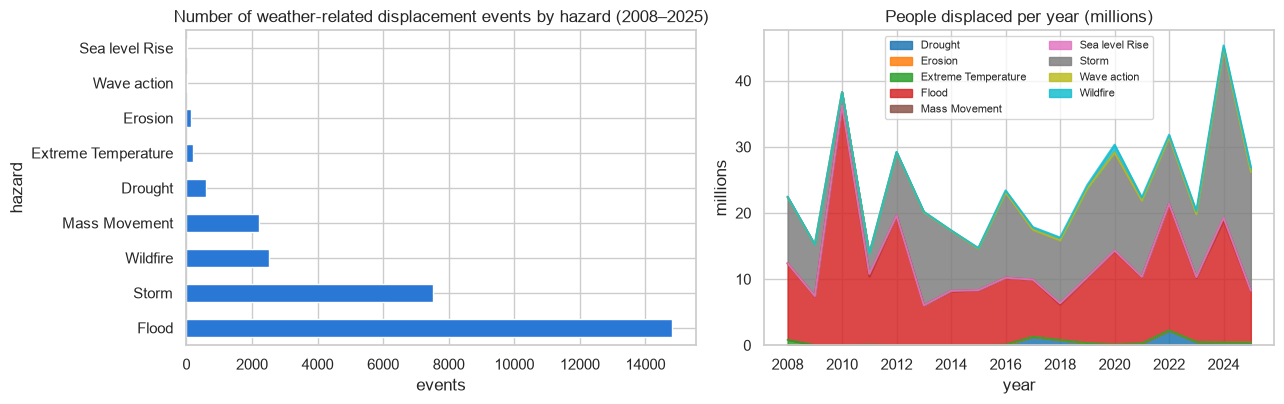

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
df["hazard"].value_counts().plot.barh(ax=axs[0], color=C_BMA)
axs[0].set_title("Number of weather-related displacement events by hazard (2008–2025)"); axs[0].set_xlabel("events")
(df.groupby(["year", "hazard"])["new_displacement"].sum().unstack().fillna(0) / 1e6).plot.area(ax=axs[1], alpha=.85, colormap="tab10")
axs[1].set_title("People displaced per year (millions)"); axs[1].set_ylabel("millions"); axs[1].legend(fontsize=8, ncol=2)
axs[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig("fig1_eda_hazards.png", dpi=160); plt.show()

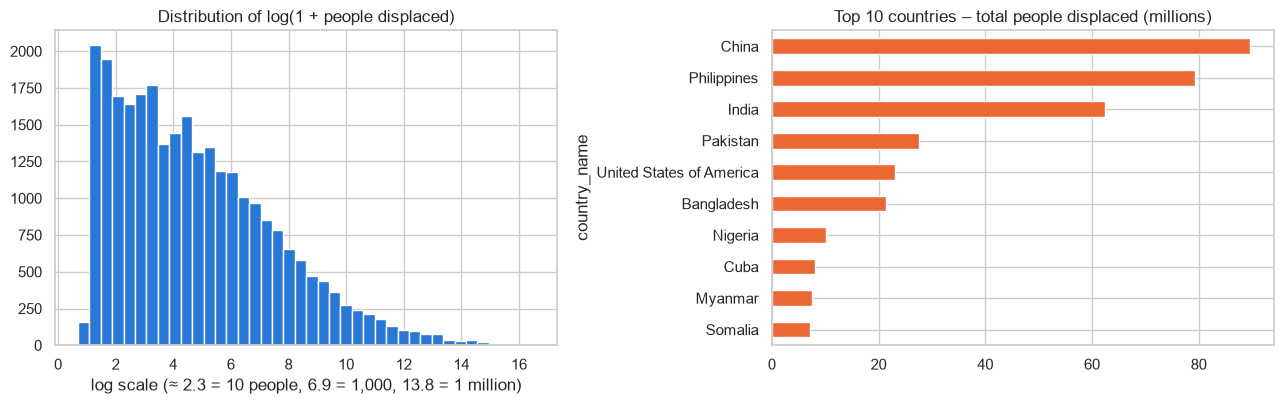

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].hist(df["y"], bins=40, color=C_BMA, edgecolor="white")
axs[0].set_title("Distribution of log(1 + people displaced)"); axs[0].set_xlabel("log scale (≈ 2.3 = 10 people, 6.9 = 1,000, 13.8 = 1 million)")
top = df.groupby("country_name")["new_displacement"].sum().nlargest(10) / 1e6
top.sort_values().plot.barh(ax=axs[1], color=C_GB)
axs[1].set_title("Top 10 countries – total people displaced (millions)")
plt.tight_layout(); plt.savefig("fig2_eda_distribution.png", dpi=160); plt.show()

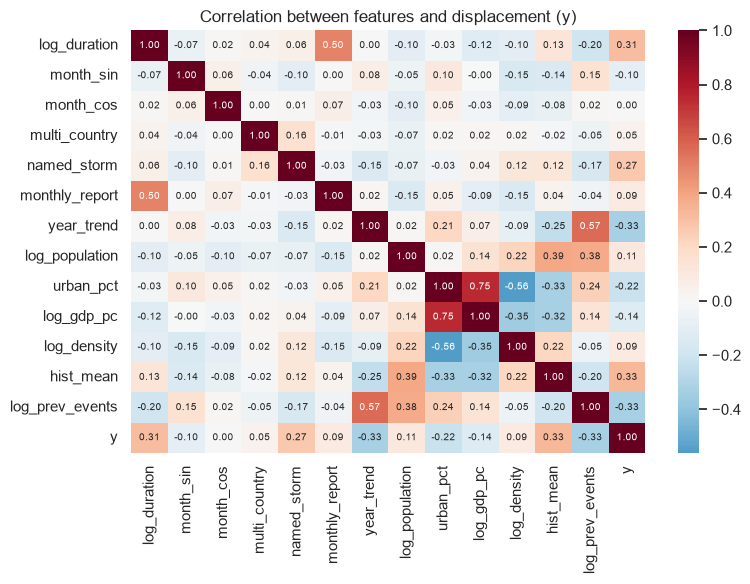

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[NUM + ["y"]].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation between features and displacement (y)"); plt.tight_layout(); plt.savefig("fig3_corr.png", dpi=160); plt.show()

## 5. Train / test split
A random **80 % / 20 %** split (fixed seed). *(Note: a strict by-year split is much harder here because IDMC has
recorded far more small events since 2023 — the data itself changed, not only the weather.)*

In [8]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, test_size=0.2, random_state=42)
mu, sd = train[NUM].mean(), train[NUM].std().replace(0, 1)
def z(d): return ((d[NUM] - mu) / sd)
Xtr_num, Xte_num = z(train), z(test)
Xtr_haz, Xte_haz = train[HAZ_COLS], test[HAZ_COLS]
ytr, yte = train["y"].values, test["y"].values
print(f"train {len(train):,} events | test {len(test):,} events")

train 22,400 events | test 5,600 events


## 6. Model 1 — Bayesian Model Averaging (BMA)
Instead of choosing **one** regression model, BMA fits **every** combination of the 10 numeric features
(2¹³ = 8,192 linear models; hazard type is always included) and averages them.
Each model's weight is its posterior probability, approximated with the BIC:

$$P(M_k\mid D) \propto \exp\left(-\tfrac{1}{2}\,\mathrm{BIC}_k\right),\qquad \mathrm{BIC}_k = n\ln(\mathrm{RSS}_k/n) + p_k\ln n$$

The BMA prediction is the weighted average, and its variance adds the within-model and between-model spread,
giving an honest uncertainty range.

In [9]:
def bma_fit(Xn, Xh, y):
    """Exact BMA over all 2^K subsets of the numeric features (hazard dummies + intercept always in).
    Uses pre-computed X'X so each of the thousands of regressions is a tiny linear solve."""
    n, K = len(y), len(NUM)
    X = np.hstack([np.ones((n, 1)), Xh.values, Xn.values])          # [intercept | hazards | numeric]
    XtX, Xty, yty = X.T @ X, X.T @ y, y @ y
    forced = list(range(1 + Xh.shape[1]))
    models = []
    for k in range(K + 1):
        for subset in itertools.combinations(range(K), k):
            idx = forced + [1 + Xh.shape[1] + i for i in subset]
            beta = np.linalg.solve(XtX[np.ix_(idx, idx)], Xty[idx])
            rss = yty - beta @ Xty[idx]; p = len(idx)
            models.append({"cols": [NUM[i] for i in subset], "idx": idx, "beta": beta,
                           "bic": n*np.log(rss/n) + p*np.log(n), "sigma2": rss/(n-p)})
    b = np.array([m["bic"] for m in models]); w = np.exp(-(b - b.min())/2); w /= w.sum()
    for m, wi in zip(models, w): m["w"] = wi
    print(f"fitted {len(models):,} regression models")
    return models

def bma_predict(models, Xn, Xh, min_w=1e-6):
    X = np.hstack([np.ones((len(Xn), 1)), Xh.values, Xn.values])
    kept = [m for m in models if m["w"] >= min_w]
    w = np.array([m["w"] for m in kept]); w /= w.sum()
    mus = np.array([X[:, m["idx"]] @ m["beta"] for m in kept]); s2 = np.array([m["sigma2"] for m in kept])
    mean = (w[:, None] * mus).sum(0)
    var = (w[:, None] * (s2[:, None] + (mus - mean) ** 2)).sum(0)
    return mean, np.sqrt(var)

bma = bma_fit(Xtr_num, Xtr_haz, ytr)
pip = pd.Series({f: sum(m["w"] for m in bma if f in m["cols"]) for f in NUM}).sort_values()
top_models = sorted(bma, key=lambda m: -m["w"])[:5]
print("Top-5 models by posterior probability:")
for m in top_models: print(f"  P={m['w']:.3f}  features={m['cols']}")
bma_tr, _ = bma_predict(bma, Xtr_num, Xtr_haz)
bma_te, bma_sd = bma_predict(bma, Xte_num, Xte_haz)

fitted 8,192 regression models
Top-5 models by posterior probability:
  P=0.782  features=['log_duration', 'month_cos', 'named_storm', 'year_trend', 'log_population', 'urban_pct', 'log_density', 'hist_mean', 'log_prev_events']
  P=0.104  features=['log_duration', 'month_cos', 'named_storm', 'monthly_report', 'year_trend', 'log_population', 'urban_pct', 'log_density', 'hist_mean', 'log_prev_events']
  P=0.069  features=['log_duration', 'month_sin', 'month_cos', 'named_storm', 'year_trend', 'log_population', 'urban_pct', 'log_density', 'hist_mean', 'log_prev_events']
  P=0.024  features=['log_duration', 'month_cos', 'multi_country', 'named_storm', 'year_trend', 'log_population', 'urban_pct', 'log_density', 'hist_mean', 'log_prev_events']
  P=0.009  features=['log_duration', 'month_sin', 'month_cos', 'named_storm', 'monthly_report', 'year_trend', 'log_population', 'urban_pct', 'log_density', 'hist_mean', 'log_prev_events']


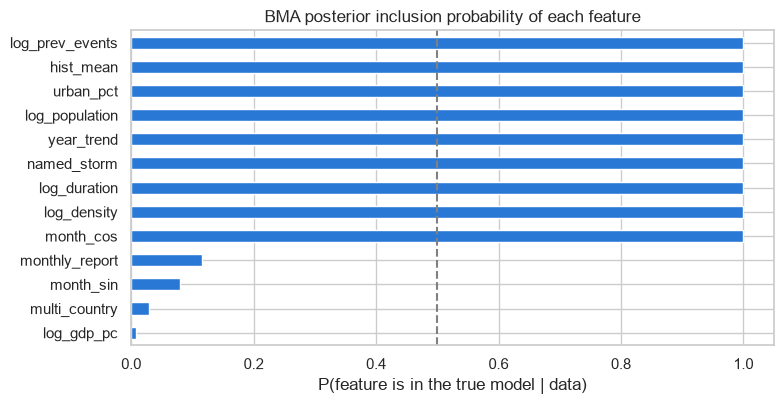

In [10]:
plt.figure(figsize=(8, 4.2))
pip.plot.barh(color=C_BMA)
plt.axvline(0.5, ls="--", color="grey"); plt.xlim(0, 1.05)
plt.title("BMA posterior inclusion probability of each feature"); plt.xlabel("P(feature is in the true model | data)")
plt.tight_layout(); plt.savefig("fig4_bma_pip.png", dpi=160); plt.show()

## 7. Model 2 — Gradient Boosting
Builds 500 small decision trees **one after another**; each new tree learns the errors (residuals) left by the
trees before it — the boosting idea from Unit 5 (AdaBoost generalised to squared-error regression).

In [11]:
Xtr_full = pd.concat([Xtr_num, Xtr_haz], axis=1); Xte_full = pd.concat([Xte_num, Xte_haz], axis=1)
gb = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, min_samples_leaf=40, random_state=42)
gb.fit(Xtr_full, ytr)
gb_te = gb.predict(Xte_full)

## 8. The hybrid — BMA + Gradient Boosting on BMA's residuals
1. **BMA** gives an interpretable baseline prediction with an uncertainty range.
2. **Gradient Boosting** is trained on what BMA got wrong (the residuals), using the features *and* BMA's own
   prediction, so it adds the non-linear patterns and interactions a linear model cannot capture.
3. **Hybrid prediction = BMA prediction + boosted correction.** The uncertainty band comes from BMA.

In [12]:
res_tr = ytr - bma_tr
Xtr_h = Xtr_full.assign(bma_pred=bma_tr); Xte_h = Xte_full.assign(bma_pred=bma_te)
gb_res = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8, min_samples_leaf=40, random_state=42)
gb_res.fit(Xtr_h, res_tr)
hyb_te = bma_te + gb_res.predict(Xte_h)

## 9. Compare the three models on the unseen test events

In [13]:
def metrics(name, pred):
    return {"Model": name, "RMSE (log)": mean_squared_error(yte, pred) ** .5, "MAE (log)": mean_absolute_error(yte, pred),
            "R²": r2_score(yte, pred),
            "Median error (people, ×)": float(np.exp(np.median(np.abs(yte - pred))))}
res = pd.DataFrame([metrics("BMA (linear, averaged)", bma_te), metrics("Gradient Boosting", gb_te),
                    metrics("Hybrid BMA + GB", hyb_te)]).set_index("Model").round(3)
res

,RMSE (log),MAE (log),R²,"Median error (people, ×)"
Model,,,,
"BMA (linear, averaged)",2.187,1.740,0.361,4.330
Gradient Boosting,1.902,1.482,0.517,3.386
Hybrid BMA + GB,1.897,1.481,0.520,3.376


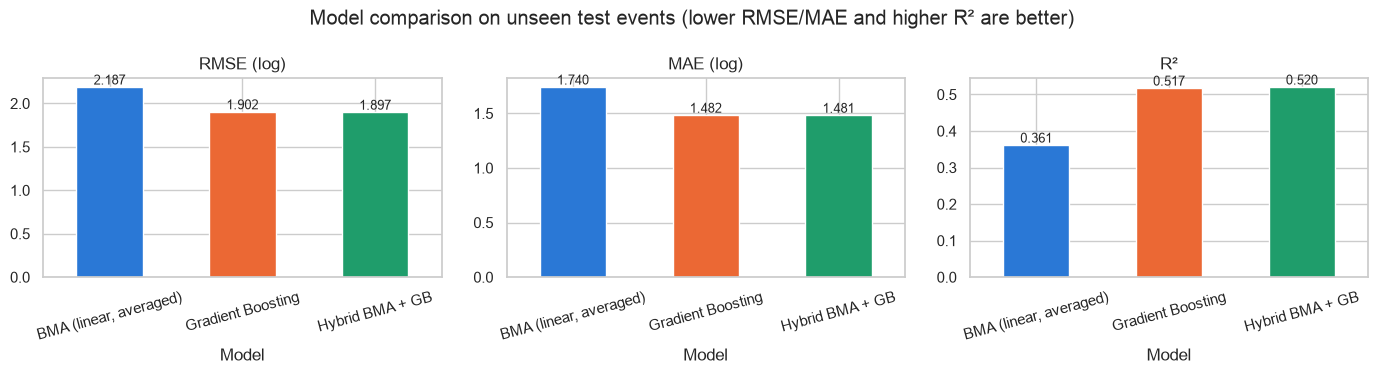

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axs, ["RMSE (log)", "MAE (log)", "R²"]):
    res[col].plot.bar(ax=ax, color=[C_BMA, C_GB, C_HYB]); ax.set_title(col); ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(res[col]): ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
plt.suptitle("Model comparison on unseen test events (lower RMSE/MAE and higher R² are better)")
plt.tight_layout(); plt.savefig("fig5_comparison.png", dpi=160); plt.show()

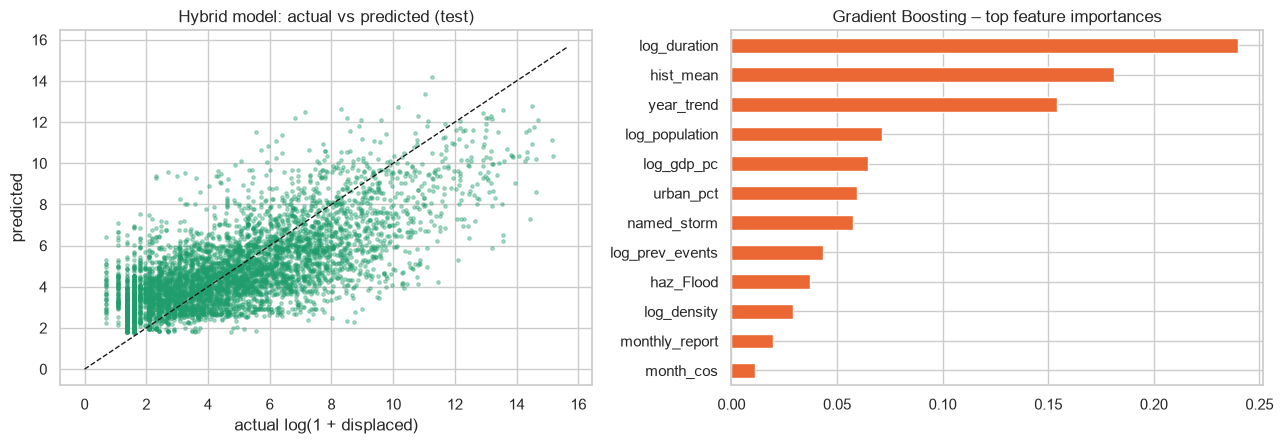

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
axs[0].scatter(yte, hyb_te, s=6, alpha=.35, color=C_HYB)
lim = [0, max(yte.max(), hyb_te.max()) + .5]; axs[0].plot(lim, lim, "k--", lw=1)
axs[0].set_xlabel("actual log(1 + displaced)"); axs[0].set_ylabel("predicted"); axs[0].set_title("Hybrid model: actual vs predicted (test)")
imp = pd.Series(gb.feature_importances_, index=Xtr_full.columns).nlargest(12).sort_values()
imp.plot.barh(ax=axs[1], color=C_GB); axs[1].set_title("Gradient Boosting – top feature importances")
plt.tight_layout(); plt.savefig("fig6_actual_vs_pred.png", dpi=160); plt.show()

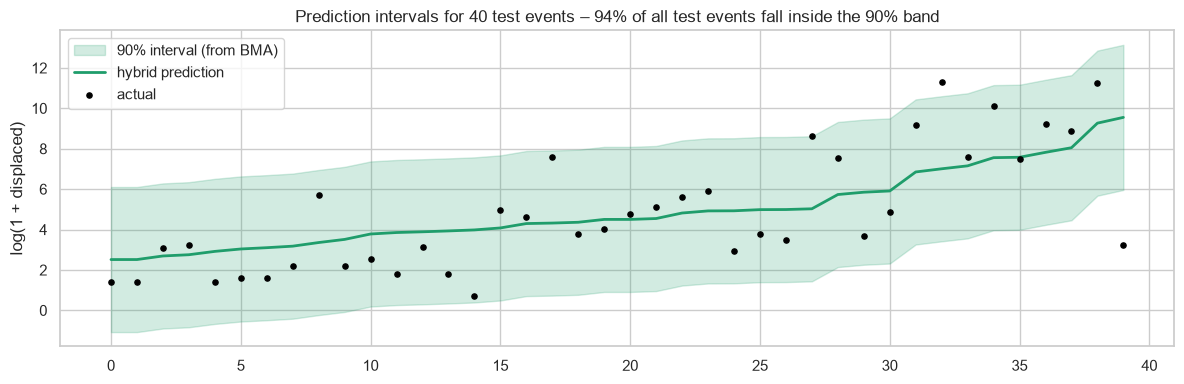

In [16]:
# Uncertainty: 90% BMA interval around the hybrid prediction for 40 random test events
idx = np.random.choice(len(yte), 40, replace=False); idx = idx[np.argsort(hyb_te[idx])]
lo, hi = hyb_te[idx] - 1.645*bma_sd[idx], hyb_te[idx] + 1.645*bma_sd[idx]
plt.figure(figsize=(12, 4))
plt.fill_between(range(40), lo, hi, color=C_HYB, alpha=.2, label="90% interval (from BMA)")
plt.plot(range(40), hyb_te[idx], color=C_HYB, lw=2, label="hybrid prediction")
plt.scatter(range(40), yte[idx], color="black", s=14, zorder=3, label="actual")
coverage = np.mean((yte >= hyb_te - 1.645*bma_sd) & (yte <= hyb_te + 1.645*bma_sd))
plt.title(f"Prediction intervals for 40 test events – {coverage:.0%} of all test events fall inside the 90% band")
plt.ylabel("log(1 + displaced)"); plt.legend(); plt.tight_layout(); plt.savefig("fig7_intervals.png", dpi=160); plt.show()

## 10. Decision support for local authorities
Turn a forecast into an aid plan using the **Sphere humanitarian standards**: at least **15 litres of water per
person per day** and **3.5 m² of covered living space per person**, plus a family tent per 5 people.

In [17]:
def plan_aid(country_iso3, hazard, month, duration_days, named_storm=0, days_of_support=7):
    base = df[df["iso3"] == country_iso3].sort_values("year").iloc[-1]       # latest country context
    row = base.copy()
    row["log_duration"], row["month_sin"], row["month_cos"] = np.log1p(duration_days), np.sin(2*np.pi*month/12), np.cos(2*np.pi*month/12)
    row["multi_country"], row["named_storm"], row["monthly_report"], row["year_trend"] = 0, named_storm, 0, 2025 - 2008
    xn = ((row[NUM].astype(float) - mu) / sd).to_frame().T
    xh = pd.DataFrame([[1.0 if c == f"haz_{hazard}" else 0.0 for c in HAZ_COLS]], columns=HAZ_COLS)
    m, s = bma_predict(bma, xn, xh)
    pred = m + gb_res.predict(pd.concat([xn, xh], axis=1).assign(bma_pred=m))
    low, mid, high = np.expm1(pred - 1.645*s)[0], np.expm1(pred)[0], np.expm1(pred + 1.645*s)[0]
    plan = pd.DataFrame({"Scenario": ["Low (5%)", "Expected", "High (95%)"],
                         "People displaced": np.round([low, mid, high]).astype(int)})
    plan["Family tents (5 people)"] = np.ceil(plan["People displaced"] / 5).astype(int)
    plan["Shelter area (m²)"] = (plan["People displaced"] * 3.5).round().astype(int)
    plan[f"Water for {days_of_support} days (litres)"] = (plan["People displaced"] * 15 * days_of_support).astype(int)
    return plan

print("Example: a 15-day monsoon flood in Bangladesh in July")
plan_aid("BGD", "Flood", month=7, duration_days=15)

Example: a 15-day monsoon flood in Bangladesh in July


,Scenario,People displaced,Family tents (5 people),Shelter area (m²),Water for 7 days (litres)
0,Low (5%),182,37,637,19110
1,Expected,6632,1327,23212,696360
2,High (95%),240419,48084,841466,25243995


In [18]:
print("Example: a named typhoon hitting the Philippines in November (3 days)")
plan_aid("PHL", "Storm", month=11, duration_days=3, named_storm=1)

Example: a named typhoon hitting the Philippines in November (3 days)


,Scenario,People displaced,Family tents (5 people),Shelter area (m²),Water for 7 days (litres)
0,Low (5%),1346,270,4711,141330
1,Expected,48810,9762,170835,5125050
2,High (95%),1769056,353812,6191696,185750880


## 11. Conclusion
* **BMA** tells us *which* factors matter and *how sure* we are (posterior inclusion probabilities, intervals).
* **Gradient Boosting** captures non-linear effects (e.g. how duration matters differently for storms and droughts).
* The **hybrid** keeps BMA's uncertainty and interpretability and adds boosting's accuracy, giving authorities a
  *range* of expected displacement that converts directly into tents, shelter space and water.